In [ ]:
import json
from pathlib import Path
import seaborn as sns
from collections import Counter
from tqdm.cli import tqdm

In [2]:
from sys import path as sys_path
project_root = Path.cwd().parent.parent
if project_root not in sys_path:
    sys_path.append(str(project_root))
data_dir = project_root/"data/"
outputs_dir = project_root/"outputs/"

In [ ]:
zero_year_page_n_counter = Counter()
zero_year_book_part_counter = Counter()

 ## Process JSONL files

In [ ]:
migration_data_directory = Path(outputs_dir / "json/migration_jsonls/2-final")
files = list(migration_data_directory.glob("*_migration_events.jsonl"))

for file in tqdm(files):
    with open(file, "r", encoding="utf-8") as f:
        for line in f:
            record = json.loads(line)
            year = record["year_prediction"]
            page_n = record["page_n"]

            if year == 0:
                zero_year_page_n_counter[page_n] += 1

                zero_year_book_part_counter[
                    # roughly book progress as percent
                    int(100 * (page_n / record["image_range_end"]))
                ] += 1

100%|██████████| 468/468 [00:33<00:00, 13.95it/s]


In [35]:
zero_year_page_n_counter_as_list = []
for page, count in zero_year_page_n_counter.items():
    zero_year_page_n_counter_as_list.extend([page] * count)

zero_year_book_part_counter_as_list = []
for part, count in zero_year_book_part_counter.items():
    zero_year_book_part_counter_as_list.extend([part] * count)

Text(0.5, 0, 'Page number')

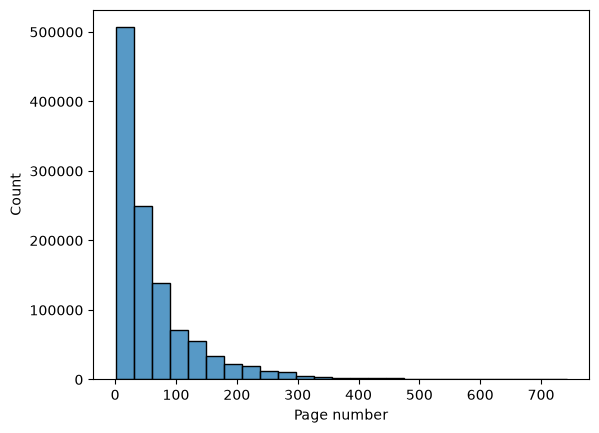

In [44]:
sns.histplot(
    zero_year_page_n_counter_as_list, bins=25,
).set_xlabel("Page number")

Text(0.5, 0, 'Progress (%)')

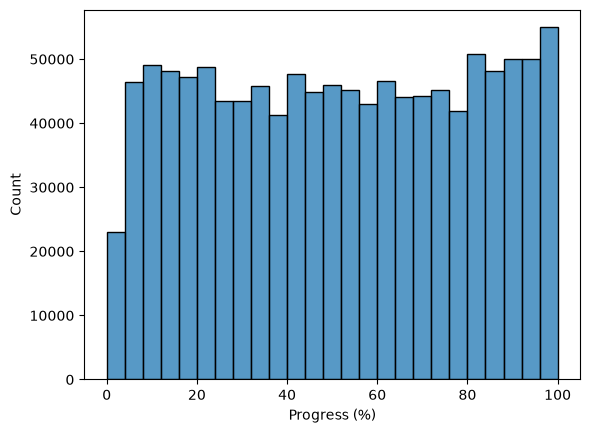

In [45]:
sns.histplot(
    zero_year_book_part_counter_as_list, bins=25
).set_xlabel("Progress (%)")